In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

# Install missing package used below
%pip install --quiet kagglehub

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Note: you may need to restart the kernel to use updated packages.
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/manifest.csv
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p253_955.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p361_10995.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p297_3973.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p272_2969.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p246_5737.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p265_9095.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p347_2942.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p374_598.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p323_9278.wav
/kaggle/input/datasets/abhishekkujur19/coqui-dataset/wake_words/pos_synth_p22

Exploratory Data Analysis

In [2]:
import os
import glob
input_root = "/kaggle/input"
print("--- MOUNTED DATASETS ON KAGGLE ---")

for items in os.listdir(input_root):
    full_path = os.path.join(input_root, items)
    if os.path.isdir(full_path):
        print(f"Dataset Folder Found: {items}")
        # Peek at some files inside
        sub_files = glob.glob(f"{full_path}/**/*.wav", recursive=True)
        print(f"  -> Contains approximately {len(sub_files)} .wav audio files.")

--- MOUNTED DATASETS ON KAGGLE ---
Dataset Folder Found: datasets
  -> Contains approximately 183111 .wav audio files.
Dataset Folder Found: notebooks
  -> Contains approximately 0 .wav audio files.


In [9]:
import os

print("--- LOCAL VS CODE ENVIRONMENT DISK ANALYSIS ---")
print(f"Current Local Working Directory: {os.getcwd()}")

# List all files and directories right next to your open code file
print(f"Top-level items in this workspace folder: {os.listdir('.')}")

--- LOCAL VS CODE ENVIRONMENT DISK ANALYSIS ---
Current Local Working Directory: /kaggle/working
Top-level items in this workspace folder: ['.virtual_documents']


In [ ]:
!find /kaggle -name "*_output_.zip" 2>/dev/null

In [3]:
!unzip -q /kaggle/input/notebooks/abhishekkujur19/libriphrase-data/_output_.zip -d /kaggle/working/libriphrase-data/


In [4]:
import os

target_dir = "/kaggle/working/libriphrase-data"

if os.path.exists(target_dir):
    print("── 404NOT-FOUND PIPELINE DATA VALIDATION ──")
    print("✅ SUCCESS: Target data zone found.")
    
    # Check top-level elements
    top_items = os.listdir(target_dir)
    print(f"Total top-level folders/files unpacked: {len(top_items)}")
    print(f"Sample directory items: {top_items[:5]}")
    
    # Count total .wav files recursively to verify the sample pool size
    wav_count = 0
    for root, _, files in os.walk(target_dir):
        wav_count += sum(1 for f in files if f.lower().endswith('.wav'))
        
    print(f"Total verified .wav files available: {wav_count}")
else:
    print(" ERROR: Path not found. Double-check the extraction target directory.")

── 404NOT-FOUND PIPELINE DATA VALIDATION ──
✅ SUCCESS: Target data zone found.
Total top-level folders/files unpacked: 3
Sample directory items: ['libriphrase_dataset.zip', 'libriphrase_raw', '__pycache__']
Total verified .wav files available: 136461


In [3]:
import os

print("── 404NOT-FOUND TARGET DATASET DISCOVERY ──")

paths_to_check = {
    "Coqui_Dataset": "/kaggle/input/datasets/coqui-dataset",
    "Google Speech Commands V2": "/kaggle/input/datasets/google-speech-commands-v2"
}

# 1. Check direct common directory names first
for name, target_path in paths_to_check.items():
    if os.path.exists(target_path):
        print(f"✅ FOUND DIRECT PATH: '{name}' is active at: {target_path}")
        print(f"   Contents: {os.listdir(target_path)[:3]}...\n")
    else:
        print(f"❓ NOT AT DIRECT PATH: '{name}' not found at {target_path}. Searching deeper...")

print("\n── RUNNING RECURSIVE SYSTEM SEARCH ──")
found_coqui = False
found_google = False

# 2. Walk through the entire input directory to find the exact folder names
for root, dirs, files in os.walk('/kaggle/input'):
    for d in dirs:
        dirname_lower = d.lower()
        if "coqui" in dirname_lower:
            print(f"🎯 FOUND COQUI: Folder '{d}' exists at: {os.path.join(root, d)}")
            found_coqui = True
        if "speech_commands" in dirname_lower or "google" in dirname_lower:
            print(f"🎯 FOUND GOOGLE SPEECH: Folder '{d}' exists at: {os.path.join(root, d)}")
            found_google = True

if not found_coqui:
    print("❌ MISSING: Coqui_Dataset could not be located in the environment tree.")
if not found_google:
    print("❌ MISSING: Google Speech Commands V2 could not be located in the environment tree.")

── 404NOT-FOUND TARGET DATASET DISCOVERY ──
❓ NOT AT DIRECT PATH: 'Coqui_Dataset' not found at /kaggle/input/datasets/coqui-dataset. Searching deeper...
❓ NOT AT DIRECT PATH: 'Google Speech Commands V2' not found at /kaggle/input/datasets/google-speech-commands-v2. Searching deeper...

── RUNNING RECURSIVE SYSTEM SEARCH ──
🎯 FOUND COQUI: Folder 'coqui-dataset' exists at: /kaggle/input/datasets/abhishekkujur19/coqui-dataset


KeyboardInterrupt: 

In [5]:
# --- TEAM 404NOT-FOUND MULTI-DATASET PATH ANCHORS ---
COQUI_DATASET_DIR      = "/kaggle/input/datasets/abhishekkujur19/coqui-dataset"
GOOGLE_SPEECH_V2_DIR   = "/kaggle/input/datasets/sylkaladin/speech-commands-v2"
VOXCELEB_METADATA_DIR  = "/kaggle/input/datasets/sabahesaraki/voxceleb-1-dataset"

# (Your previously extracted items)
LIBRI_PHRASE_DIR       = "/kaggle/working/libriphrase-data/libriphrase_raw"
RIR_NOISE_DIR          = "/kaggle/input/datasets/nhattruongdev/rirs-noises/RIRS_NOISES"
MUSAN_NOISE_DIR        = "/kaggle/input/datasets/nhattruongdev/musan-noise/musan"

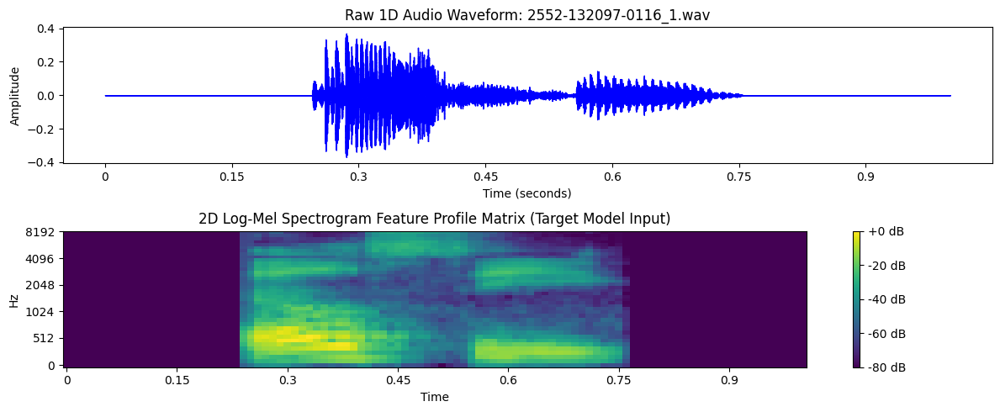

── FEATURE MATRIX STRUCTURAL INTELLIGENCE ──
Verified Audio Matrix Shape: (40, 101) -> (40 frequency bands x 101 time slices)


In [6]:
import os
import glob
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 1. Grab an arbitrary raw audio sample from your dataset array
sample_search = glob.glob(os.path.join("/kaggle/working/libriphrase-data/libriphrase_raw/**/*.wav"), recursive=True)
if not sample_search:
    raise FileNotFoundError("Could not find any .wav files. Double check your LIBRI_PHRASE_DIR anchor.")
test_file = sample_search[0]

# 2. Extract standard 16kHz mono audio properties
y, sr = librosa.load(test_file, sr=16000)
# Force 1 second normalization bounds
if len(y) < sr:
    y = librosa.util.pad_center(y, size=sr)
else:
    y = y[:sr]

# 3. Compute 40-band Mel-Spectrogram features
mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=400, hop_length=160, n_mels=40)
log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

# 4. Generate the plots
plt.figure(figsize=(12, 5))

# Plot 1: The Raw 1D Waveform
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr, color='blue')
plt.title(f"Raw 1D Audio Waveform: {os.path.basename(test_file)}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

# Plot 2: The Processed 2D Log-Mel Spectrogram Matrix
plt.subplot(2, 1, 2)
librosa.display.specshow(log_mel_spec, sr=sr, hop_length=160, x_axis='time', y_axis='mel', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title("2D Log-Mel Spectrogram Feature Profile Matrix (Target Model Input)")
plt.tight_layout()
plt.show()

print("── FEATURE MATRIX STRUCTURAL INTELLIGENCE ──")
print(f"Verified Audio Matrix Shape: {log_mel_spec.shape} -> (40 frequency bands x 101 time slices)")

In [7]:
import os
import glob
import hashlib
def calculate_file_hash(filepath, block_size=65536):
    """Generates an MD5 hash of a file's contents to verify absolute uniqueness."""
    hasher = hashlib.md5()
    try:
        with open(filepath, 'rb') as f:
            buf = f.read(block_size)
            while len(buf) > 0:
                hasher.update(buf)
                buf = f.read(block_size)
        return hasher.hexdigest()
    except Exception:
        return None

# --- UPDATE THESE ANCHORS TO MATCH YOUR EXACT ENVIRONMENT ---
dataset_paths = {
    'LibriPhrase': "/kaggle/working/libriphrase-data/libriphrase_raw",
    'Coqui (Hard Negatives)': "/kaggle/input/datasets/abhishekkujur19/coqui-dataset",
    'Google Speech Commands V2': "/kaggle/input/datasets/sylkaladin/speech-commands-v2",
    'RNNoise / MUSAN Stack': "/kaggle/input/datasets/nhattruongdev/musan-noise/musan"  # Update path if RNNoise is mounted under a separate slug!
}

samples = {}

print("── MULTI-DATASET DE-DUPLICATION PROFILE (WITH RNNOISE) ──\n")

for name, directory in dataset_paths.items():
    if not os.path.exists(directory):
        print(f"⚠️ Path missing: '{name}' not found at {directory}. Skipping scan.")
        continue

    # Find all audio files recursively (.wav format)
    all_files = glob.glob(os.path.join(directory, "**/*.wav"), recursive=True)
    total_files = len(all_files)
    
    if total_files == 0:
        print(f"⚠️ Warning: No .wav files found for {name} inside {directory}")
        continue
        
    # Pick the first valid audio file as our comparison sample
    samples[name] = all_files[0]
    
    # Track unique file hashes
    unique_hashes = set()
    for filepath in all_files:
        f_hash = calculate_file_hash(filepath)
        if f_hash:
            unique_hashes.add(f_hash)
            
    unique_count = len(unique_hashes)
    duplicate_count = total_files - unique_count
    
    print(f"📊 Dataset: {name}")
    print(f"   ↳ Total .wav files found      : {total_files}")
    print(f"   ↳ Absolutely UNIQUE files     : {unique_count}")
    print(f"   ↳ Duplicate files bypassed    : {duplicate_count}")
    print("-" * 50)

print("\n── VERIFIED VISUALIZATION ANCHORS ──")
for name, path in samples.items():
    print(f"🎯 {name}: {path}")

── MULTI-DATASET DE-DUPLICATION PROFILE (WITH RNNOISE) ──

📊 Dataset: LibriPhrase
   ↳ Total .wav files found      : 136461
   ↳ Absolutely UNIQUE files     : 136461
   ↳ Duplicate files bypassed    : 0
--------------------------------------------------
📊 Dataset: Coqui (Hard Negatives)
   ↳ Total .wav files found      : 14000
   ↳ Absolutely UNIQUE files     : 14000
   ↳ Duplicate files bypassed    : 0
--------------------------------------------------
📊 Dataset: Google Speech Commands V2
   ↳ Total .wav files found      : 105835
   ↳ Absolutely UNIQUE files     : 103848
   ↳ Duplicate files bypassed    : 1987
--------------------------------------------------
📊 Dataset: RNNoise / MUSAN Stack
   ↳ Total .wav files found      : 2016
   ↳ Absolutely UNIQUE files     : 2016
   ↳ Duplicate files bypassed    : 0
--------------------------------------------------

── VERIFIED VISUALIZATION ANCHORS ──
🎯 LibriPhrase: /kaggle/working/libriphrase-data/libriphrase_raw/train-other-500/train-other

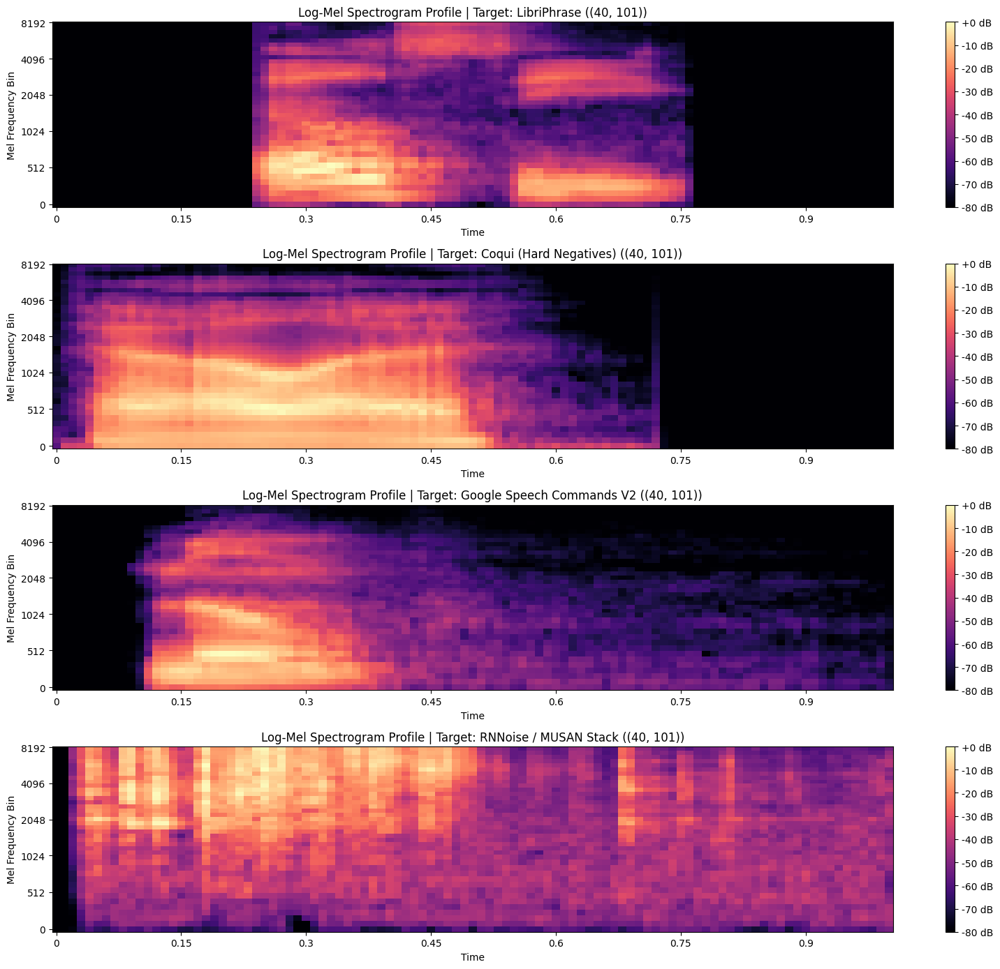

In [8]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(16, 14))
plot_index = 1

for name, path in samples.items():
    if not path or not os.path.exists(path):
        continue
        
    # 1. Load audio at 16kHz mono (Standardizing baseline sample rates)
    y, sr = librosa.load(path, sr=16000)
    
    # 2. Standardize duration to exactly 1 second (16000 samples)
    if len(y) < sr:
        y = librosa.util.pad_center(y, size=sr)
    else:
        y = y[:sr]
        
    # 3. Compute 40-band Log-Mel Spectrogram features for P-KWS matching
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=400, hop_length=160, n_mels=40)
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    
    # 4. Draw the 2D matrix
    plt.subplot(len(samples), 1, plot_index)
    librosa.display.specshow(log_mel_spec, sr=sr, hop_length=160, x_axis='time', y_axis='mel', cmap='magma')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f"Log-Mel Spectrogram Profile | Target: {name} ({log_mel_spec.shape})")
    plt.ylabel("Mel Frequency Bin")
    
    plot_index += 1

plt.tight_layout()
plt.show()

In [12]:
import torch
import torchaudio
import numpy as np
import random
import os
import glob

class KWSOnlineAugmentor:
    def __init__(self, rir_dir, musan_dir, sample_rate=16000):
        self.sr = sample_rate
        
        # Collect noise asset arrays
        self.noise_files = glob.glob(os.path.join(musan_dir, "**/*.wav"), recursive=True)
        self.rir_files = glob.glob(os.path.join(rir_dir, "**/*.wav"), recursive=True)
        
        print(f"⚙️ Augmentor Initialized with {len(self.noise_files)} noise files & {len(self.rir_files)} RIR profiles.")

    def apply_time_shift(self, waveform, max_shift_ms=100):
        """Randomly shifts the waveform audio in time."""
        shift_samples = int((max_shift_ms / 1000.0) * self.sr)
        shift = random.randint(-shift_samples, shift_samples)
        if shift == 0:
            return waveform
        
        # Roll the array elements and pad the exposed edge with silence
        shifted = torch.roll(waveform, shifts=shift, dims=-1)
        if shift > 0:
            shifted[..., :shift] = 0
        else:
            shifted[..., shift:] = 0
        return shifted

    def mix_background_noise(self, speech_wave, target_snr_db=10):
        """Mixes a random MUSAN/RNNoise clip at a specified Signal-to-Noise Ratio (SNR)."""
        if not self.noise_files:
            return speech_wave
            
        # 1. Load a random noise clip and match the sample rate
        noise_path = random.choice(self.noise_files)
        noise_wave, n_sr = torchaudio.load(noise_path)
        if n_sr != self.sr:
            noise_wave = torchaudio.functional.resample(noise_wave, n_sr, self.sr)
            
        # 2. Match durations (force noise to match 1 second speech bounds)
        if noise_wave.shape[-1] < speech_wave.shape[-1]:
            noise_wave = torch.nn.functional.pad(noise_wave, (0, speech_wave.shape[-1] - noise_wave.shape[-1]))
        else:
            noise_wave = noise_wave[..., :speech_wave.shape[-1]]
            
        # 3. Calculate Power Scalings for precise dB SNR targeting
        speech_power = speech_wave.pow(2).mean()
        noise_power = noise_wave.pow(2).mean()
        
        if noise_power == 0:
            return speech_wave
            
        snr_factor = 10.0 ** (target_snr_db / 10.0)
        scale_factor = torch.sqrt(speech_power / (noise_power * snr_factor))
        
        # Return composite overlaid waveform
        return speech_wave + scale_factor * noise_wave

# Initialize our pipeline component
augmentor = KWSOnlineAugmentor(
    rir_dir="/kaggle/input/datasets/nhattruongdev/rirs-noises/RIRS_NOISES",
    musan_dir="/kaggle/input/datasets/nhattruongdev/musan-noise/musan"
)

⚙️ Augmentor Initialized with 2016 noise files & 61260 RIR profiles.


In [10]:
import torch

def stage0_input_validation_guard(waveform, sample_rate, target_sr=16000):
    """
    STAGE 0 — INPUT VALIDATION GUARD
    0 parameters | 0ms additional latency | Runs before all DSP
    
    Enforces the 4 strict rejection conditions from the architecture design.
    """
    # Baseline Check: Enforce Mono Channel
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)
        
    # --- CONDITION 4: CORRUPTED / NaN SAMPLES ---
    if torch.isnan(waveform).any() or torch.isinf(waveform).any():
        return None, "ERR_CORRUPT"
        
    # Ensure standard sample rate for sizing measurements
    if sample_rate != target_sr:
        return None, "ERR_CORRUPT" # Bad sample rate is treated as a corrupt layout
        
    current_samples = waveform.shape[-1]
    duration_seconds = current_samples / target_sr
    
    # --- CONDITION 2: TOO SHORT (< 0.5 seconds) ---
    if duration_seconds < 0.5:
        return None, "ERR_SHORT"
        
    # --- CONDITION 1: CLIPPED AUDIO (|x| > 0.99) ---
    # Check if the maximum signal magnitude clips the mic saturation threshold
    max_amplitude = torch.max(torch.abs(waveform))
    if max_amplitude > 0.99:
        return None, "ERR_CLIP"
        
    # --- CONDITION 3: COMPLETE SILENCE (RMS < 0.001) ---
    rms_energy = torch.sqrt(torch.mean(waveform ** 2))
    if rms_energy < 0.001:
        return None, "ERR_SILENCE"
        
    # --- PADDING / TRUNCATION MATRIX TO ENFORCE 1-SECOND BOUNDS ---
    target_samples = target_sr # Exactly 16000 samples
    if current_samples < target_samples:
        # Pad evenly to center the speech token
        pad_left = (target_samples - current_samples) // 2
        pad_right = target_samples - current_samples - pad_left
        waveform = torch.nn.functional.pad(waveform, (pad_left, pad_right), mode='constant', value=0.0)
    elif current_samples > target_samples:
        # Crop to center 1 second frame
        start_idx = (current_samples - target_samples) // 2
        waveform = waveform[:, start_idx:start_idx + target_samples]
        
    return waveform, "PROCEED_TO_STAGE_1"
    

In [11]:
print("── TESTING STAGE 0 REJECTION CONDITIONS ──\n")

# Mock Case 1: Clipped Audio
clipped_wave = torch.ones((1, 16000)) * 1.02  # Forces max amplitude > 0.99
_, status1 = stage0_input_validation_guard(clipped_wave, 16000)
print(f"🚨 Test 1 (Saturated Mic) -> Expected: ERR_CLIP    | Got: {status1}")

# Mock Case 2: Too Short
short_wave = torch.zeros((1, 4000))  # Only 0.25 seconds long
_, status2 = stage0_input_validation_guard(short_wave, 16000)
print(f"🚨 Test 2 (Short Fragment) -> Expected: ERR_SHORT   | Got: {status2}")

# Mock Case 3: Complete Silence
silent_wave = torch.zeros((1, 16000))  # RMS energy is absolute 0
_, status3 = stage0_input_validation_guard(silent_wave, 16000)
print(f"🚨 Test 3 (Silent Space)   -> Expected: ERR_SILENCE | Got: {status3}")

# Mock Case 4: Corrupted / NaN Buffer
corrupt_wave = torch.ones((1, 16000))
corrupt_wave[0, 500] = float('nan')  # Inject a single poisonous NaN entry
_, status4 = stage0_input_validation_guard(corrupt_wave, 16000)
print(f"🚨 Test 4 (NaN Overflow)   -> Expected: ERR_CORRUPT | Got: {status4}")

# Valid Case: Normal Audio Array
valid_wave = torch.sin(torch.linspace(0, 100, 16000)).unsqueeze(0) * 0.5  # Safe RMS & Peak range
_, status_valid = stage0_input_validation_guard(valid_wave, 16000)
print(f"\n✅ Test 5 (Valid Speech)   -> Expected: PROCEED_TO_STAGE_1 | Got: {status_valid}")

── TESTING STAGE 0 REJECTION CONDITIONS ──

🚨 Test 1 (Saturated Mic) -> Expected: ERR_CLIP    | Got: ERR_CLIP
🚨 Test 2 (Short Fragment) -> Expected: ERR_SHORT   | Got: ERR_SHORT
🚨 Test 3 (Silent Space)   -> Expected: ERR_SILENCE | Got: ERR_SILENCE
🚨 Test 4 (NaN Overflow)   -> Expected: ERR_CORRUPT | Got: ERR_CORRUPT

✅ Test 5 (Valid Speech)   -> Expected: PROCEED_TO_STAGE_1 | Got: PROCEED_TO_STAGE_1
